## 02 · Manifold / Trajectory

Fit an scFates PPT principal tree to the cell-state manifold. The embedding is **branching** — a clean three-tip wishbone — so a `tree` is the right topology (not a `curve`). Root at the Gast/pSom convergence hub (developmentally early), infer pseudotime, and name milestones. Node count is scaled to this ~10k-cell manifold (N=60), well below Puram's 200 over 2.4k cells.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import scanpy as sc
import scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]
pth      = os.path.join(*(['..'] * 6))
pth_in   = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_out  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)

In [3]:
# load processed data from h5ad file
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad')); adata

Out[3]: 
AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'phase_colors', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'


AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'phase_colors', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

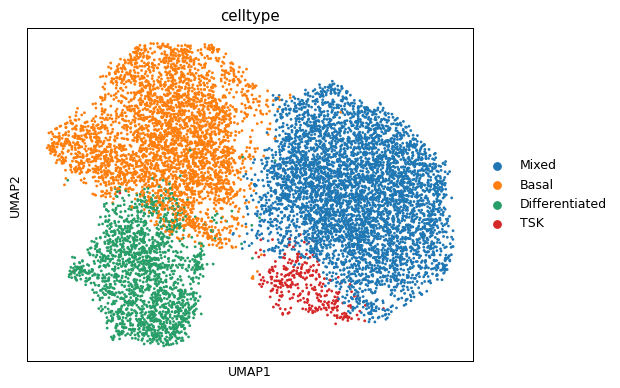

In [4]:
# visual inspection — loaded manifold, coloured by subtype
sc.pl.umap(adata, color = 'celltype', size = 20)

inferring a principal tree --> parameters used 
    60 principal points, sigma = 1.5, lambda = 2000, metric = euclidean
    fitting:  26%|##6       | 13/50 [00:01<00:03, 10.36it/s]
    converged
    finished (0:00:01) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.


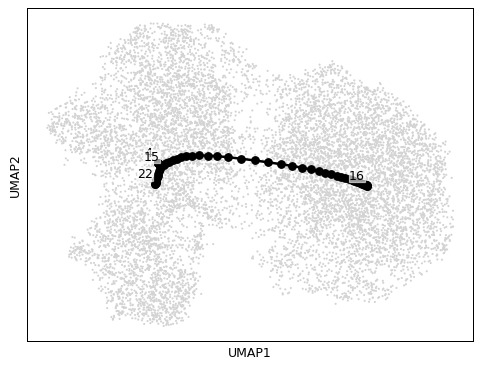

In [5]:
# fit principal tree to the cell-state manifold.
# N=60/lambda=2000/sigma=1.5 gives a clean 3-tip wishbone (1 fork); higher node
# counts over-fit spurious side-branches, lower lambda collapses the fork to a line.
scf.tl.tree(adata, method = 'ppt', Nodes = 60,
            ppt_lambda = 2000, ppt_sigma = 1.5,
            use_rep = 'X_umap', seed = 1, plot = True, basis = 'umap')

In [6]:
# set the root at the Gast/pSom convergence hub (the 'Mixed' population).
# Developmentally Gast/pSom are early and Crest is a late/terminal readout, so the
# hub — not a Crest tip — is the origin. The hub is a TIP of the tree here, not the
# fork: the bifurcation opens downstream of the convergence.
scf.tl.root(adata, 16)

node 16 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


In [7]:
# infer cell-state gradients (pseudotime)
scf.tl.pseudotime(adata, n_jobs = 4, seed = 1)

projecting cells onto the principal graph
    finished (0:00:06) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


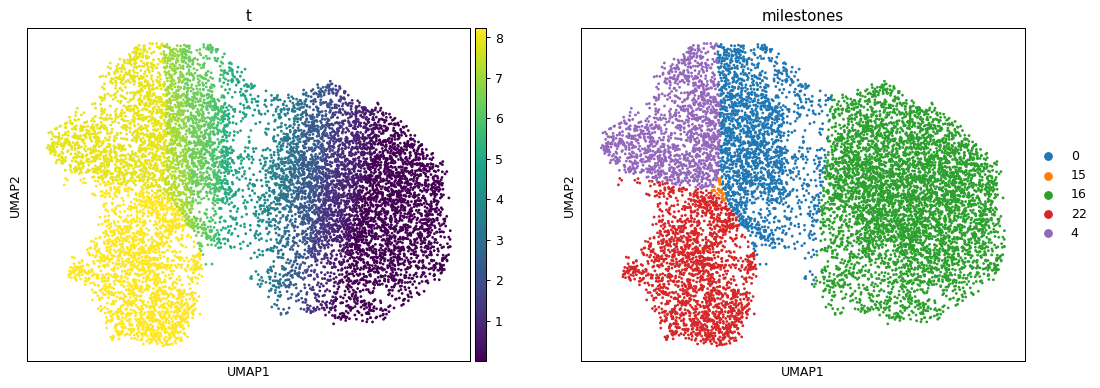

In [8]:
# visual inspection — pseudotime + milestones
sc.pl.umap(adata, color = ['t', 'milestones'], size = 20)

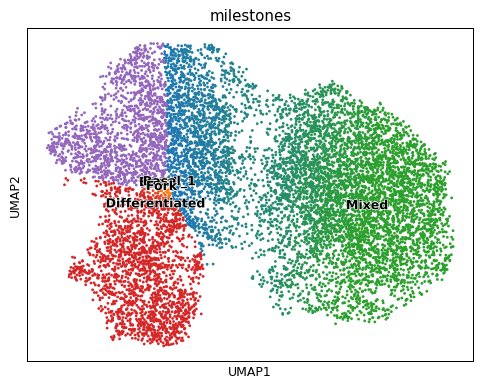

In [9]:
# rename milestones by their biology: hub (root) -> two arms.
# Milestone 16 = Gast/pSom hub (root); the fork (15) opens into a Basal/Gast arm
# (milestones 0, 4) and a Differentiated/pSom arm (milestone 22).
scf.tl.rename_milestones(adata, new = {
    '16' : 'Mixed',
    '15' : 'Fork',
    '0'  : 'Basal_1',
    '4'  : 'Basal',
    '22' : 'Differentiated'})
scf.pl.milestones(adata, basis = 'umap', annotate = True, s = 20)

In [10]:
# save manifold to h5ad file
adata.write(os.path.join(pth_in, 'manifold.h5ad'))
print('saved', os.path.join(pth_in, 'manifold.h5ad'))

saved ../../../../../../data/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-7/manifold.h5ad


saved ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-7/manifold.pdf


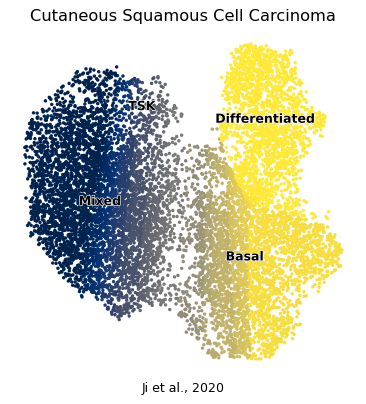

In [11]:
# save manifold embedding figure (pseudotime + milestone labels)
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 't', cmap = 'cividis', size = 30,
           colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 30, alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1,
           frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Cutaneous Squamous Cell Carcinoma', size = 13)
ax.text(.5, -.05, 'Ji et al., 2020', ha = 'center', transform = ax.transAxes)
fn = os.path.join(pth_out, 'manifold.pdf')
plt.savefig(fn, bbox_inches = 'tight'); print('saved', fn)